# 01 — Feature Inventory

**Purpose:** establish integrity, coverage, missingness, and the basic statistical profile of the model-facing feature dataset before regime modeling.

This notebook:
- opens `research.duckdb` in **read-only** mode;
- treats `time_series_feature_state` as the primary model-facing dataset;
- inspects the long-form option and L2-distribution tables when available;
- checks duplicates, temporal continuity, readiness coverage, missingness, infinities, constants, and extreme values;
- does **not** standardize, winsorize, impute, or mutate data.

> Research rule: notebooks discover; production Python modules implement accepted transformations.

## 1. Environment and read-only database connection

In [76]:
from pathlib import Path
import os
import math
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"

if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")  # hour-of-day results must be UTC

print(f"Research DB: {DB_PATH}")
print("Connection mode: read-only")

Research DB: D:\MarketData\Deribit\database\research.duckdb
Connection mode: read-only


## 2. Feature-layer relation inventory

In [77]:
relations = con.execute(
    """
    SELECT table_schema, table_name, table_type
    FROM information_schema.tables
    WHERE table_schema NOT IN ('information_schema', 'pg_catalog')
    ORDER BY table_schema, table_name
    """
).df()

feature_relations = [
    "time_series_feature_state",
    "option_surface_feature_state",
    "primary_option_surface_feature_state",
    "l2_instability_distribution_state",
]

display(relations[relations["table_name"].isin(feature_relations)].reset_index(drop=True))

missing_relations = [name for name in feature_relations if name not in set(relations["table_name"])]
print("Missing relations:" if missing_relations else "All expected feature-layer relations are present.", missing_relations)

,table_schema,table_name,table_type
0,main,l2_instability_distribution_state,BASE TABLE
1,main,option_surface_feature_state,BASE TABLE
2,main,primary_option_surface_feature_state,BASE TABLE
3,main,time_series_feature_state,BASE TABLE


All expected feature-layer relations are present. []


## 3. Load the model-facing state table

Expected grain: **one row = one underlying × one 5-minute state**.

In [78]:
features = con.execute(
    """
    SELECT *
    FROM time_series_feature_state
    ORDER BY state_time, underlying
    """
).df()

print(f"Rows:    {len(features):,}")
print(f"Columns: {features.shape[1]:,}")
display(features.head())

Rows:    34,272
Columns: 223


,state_id,state_time,underlying,session_id,expiry_date,session_start,session_end,minutes_to_expiry,is_opening_state,utc_hour,utc_minute_of_day,utc_day_of_week,is_weekend,expiry_type,us_dst,eu_dst,perp_integrity_ok,integrity_flag_count,known_exchange_event,integrity_flag_no_two_sided,integrity_flag_wide_spread,integrity_flag_mid_off_index,integrity_flag_frozen_with_trades,integrity_flag_no_l2_updates,integrity_flag_rest_stale,integrity_flag_trades_outside_bbo,in_settlement_window,settlement_locked_fraction,minutes_since_session_start,session_progress_fraction,collection_complete,price_features_ready,state_research_ready,l2_boundary_ready,l2_intrawindow_ready,futures_instrument_name,futures_tradable_mid_price,futures_mark_price,futures_index_price,futures_underlying_price,market_reference_price,market_reference_source,market_reference_is_tradable,futures_ticker_age_ms,futures_spread_bps,perpetual_mid_vs_index_bps,perpetual_mark_vs_index_bps,microprice_vs_mid_bps,return_input_eligible,index_base_eligible,open,high,low,close,vwap,volume_usd,buy_volume_usd,sell_volume_usd,trade_count,open_interest,book_stats_coverage_ms,book_stats_complete,book_update_count,book_twa_spread,book_twa_obi_5,book_twa_obi_10,book_twa_obi_20,book_twa_bid_depth_20,book_twa_ask_depth_20,book_twa_microprice,book_min_obi_20,book_max_obi_20,book_twa_abs_obi_20,book_obi_20_std,book_obi_20_path_roughness_per_min,book_obi_20_range,book_obi_20_coherence_noise,book_obi_20_transition_count,book_obi_20_raw_zero_cross_count,book_obi_20_raw_zero_cross_rate,book_obi_20_reversal_strength_mean,book_obi_20_reversal_strength_max,index_return_input_eligible,return_5m,return_15m,return_30m,return_1h,perp_mid_return_5m,return_source,log1p_volume_usd,signed_volume_usd,trade_flow_imbalance,buy_volume_share,average_trade_size_usd,intrabar_range_bps,close_vs_vwap_bps,open_interest_change_5m,open_interest_return_5m,book_twa_spread_bps,book_twa_microprice_vs_reference_bps,...,option_iv_atm_forward,option_skew_025,option_skew_050,option_curvature_025,option_curvature_050,option_local_skew_slope_025,option_local_skew_slope_050,core_smile_quality_tier,core_smile_tight,core_smile_usable,wing_050_usable,full_grid_usable,core_max_interpolation_span,wing_050_max_interpolation_span,full_grid_max_interpolation_span,option_base_eligible_rows,option_two_sided_eligible_rows,option_median_two_sided_spread_bps,option_p90_two_sided_spread_bps,atm_iv_change_5m,atm_iv_change_15m,atm_iv_change_1h,skew_025_change_5m,skew_025_change_15m,skew_025_change_1h,curvature_025_change_5m,curvature_025_change_15m,curvature_025_change_1h,skew_050_change_5m,core_surface_change_5m_ready,iv_put_25d,iv_call_25d,rr_25d,bf_25d,iv_put_10d,iv_call_10d,rr_10d,bf_10d,delta_25d_smile_available,full_delta_smile_available,max_delta_interpolation_span,median_delta_interpolation_span,rr_25d_change_5m,bf_25d_change_5m,option_snapshot_ready,src_k_m050,src_k_m025,src_k_000,src_k_p025,src_k_p050,core_iv_source_signature,wing_050_iv_source_signature,rr_25d_iv_source_signature,bf_25d_iv_source_signature,core_nodes_with_mark,node_mark_share,base_mark_iv_rows,base_mark_iv_row_share,core_source_switch_5m,atm_source_switch_5m,fit_ok,fit_n_quotes,fit_n_quotes_z1,fit_z_min,fit_z_max,fit_atm_iv,fit_skew,fit_curvature,fit_skew_rel,fit_curvature_rel,fit_wrmse,fit_atm_iv_change_5m,fit_atm_iv_change_15m,fit_atm_iv_change_30m,fit_atm_iv_change_1h,fit_skew_change_5m,fit_skew_change_15m,fit_skew_change_30m,fit_skew_change_1h,fit_curvature_change_5m,fit_curvature_change_15m,fit_curvature_change_30m,fit_curvature_change_1h,atm_iv_change_30m,skew_025_change_30m,curvature_025_change_30m,option_atm_quote_ok,option_shape_quote_ok,otm_contracts_z1,otm_with_bid_z1,otm_with_ask_z1,otm_contracts_z2,otm_with_bid_z2,otm_with_ask_z2,otm_bid_share_z2,delta_25d_change_5m_ready,structural_level_features_ready,structural_dynamic_features_ready,microstructure_features_ready,instability_features_ready
0,AVAX|2026-09-19T08:00:00Z,2026-09-19 08:00:00+00:00,AVAX,expir

## 4. Dataset identity and coverage

In [79]:
overview = pd.Series({
    "rows": len(features),
    "columns": features.shape[1],
    "unique_state_ids": features["state_id"].nunique(dropna=True),
    "underlyings": features["underlying"].nunique(dropna=True),
    "first_state": features["state_time"].min(),
    "last_state": features["state_time"].max(),
    "first_expiry": features["expiry_date"].min(),
    "last_expiry": features["expiry_date"].max(),
}, name="value").to_frame()

display(overview)

,value
rows,34272
columns,223
unique_state_ids,34272
underlyings,7
first_state,2026-09-19 08:00:00+00:00
last_state,2026-10-06 07:55:00+00:00
first_expiry,2026-09-20 00:00:00
last_expiry,2026-10-06 00:00:00


In [80]:
asset_counts = (
    features.groupby("underlying", dropna=False)
    .agg(
        rows=("state_id", "size"),
        unique_states=("state_id", "nunique"),
        first_state=("state_time", "min"),
        last_state=("state_time", "max"),
        research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
    )
    .reset_index()
)
asset_counts["research_ready_pct"] = 100.0 * asset_counts["research_ready"] / asset_counts["rows"]
display(asset_counts)

,underlying,rows,unique_states,first_state,last_state,research_ready,research_ready_pct
0,AVAX,4896,4896,2026-09-19 08:00:00+00:00,2026-10-06 07:55:00+00:00,4211,86.008987
1,BTC,4896,4896,2026-09-19 08:00:00+00:00,2026-10-06 07:55:00+00:00,4211,86.008987
2,ETH,4896,4896,2026-09-19 08:00:00+00:00,2026-10-06 07:55:00+00:00,4211,86.008987
3,HYPE,4896,4896,2026-09-19 08:00:00+00:00,2026-10-06 07:55:00+00:00,4211,86.008987
4,SOL,4896,4896,2026-09-19 08:00:00+00:00,2026-10-06 07:55:00+00:00,4211,86.008987
5,TRX,4896,4896,2026-09-19 08:00:00+00:00,2026-10-06 07:55:00+00:00,4211,86.008987
6,XRP,4896,4896,2026-09-19 08:00:00+00:00,2026-10-06 07:55:00+00:00,4211,86.008987


In [81]:
expiry_counts = (
    features.groupby("expiry_date", dropna=False)
    .agg(
        rows=("state_id", "size"),
        underlyings=("underlying", "nunique"),
        research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
        structural_level=("structural_level_features_ready", lambda s: int(s.fillna(False).sum())),
        structural_dynamic=("structural_dynamic_features_ready", lambda s: int(s.fillna(False).sum())),
        microstructure=("microstructure_features_ready", lambda s: int(s.fillna(False).sum())),
        instability=("instability_features_ready", lambda s: int(s.fillna(False).sum())),
    )
    .reset_index()
)

for col in ["research_ready", "structural_level", "structural_dynamic", "microstructure", "instability"]:
    expiry_counts[f"{col}_pct"] = 100.0 * expiry_counts[col] / expiry_counts["rows"]

display(expiry_counts)

,expiry_date,rows,underlyings,research_ready,structural_level,structural_dynamic,microstructure,instability,research_ready_pct,structural_level_pct,structural_dynamic_pct,microstructure_pct,instability_pct
0,2026-09-20,2016,7,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000
1,2026-09-21,2016,7,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000
2,2026-09-22,2016,7,1778,1645,1298,0,0,88.194444,81.597222,64.384921,0.000000,0.000000
3,2026-09-23,2016,7,1967,1939,1423,1889,0,97.569444,96.180556,70.585317,93.700397,0.000000
4,2026-09-24,2016,7,1988,1967,1509,1994,0,98.611111,97.569444,74.851190,98.908730,0.000000
5,2026-09-25,2016,7,1974,1939,1477,1980,0,97.916667,96.180556,73.263889,98.214286,0.000000
6,2026-09-26,2016,7,1960,1911,1217,1966,0,97.222222,94.791667,60.367063,97.519841,0.000000
7,2026-09-27,2016,7,2009,2009,1685,2015,0,99.652778,99.652778,83.581349,99.950397,0.000000
8,2026-09-28,2016,7,2009,2009,1640,2016,0,99.652778,99.652778,81.349206,100.000000,0.000000
9,2026-09-29,2016,7,1953,1918,1410,1958,0,96.875000,95.138889,69.940476,97.123016,0.000000


## 5. Uniqueness checks

In [82]:
duplicate_state_ids = int(features["state_id"].duplicated().sum())
duplicate_underlying_times = int(features.duplicated(subset=["underlying", "state_time"]).sum())

print(f"Duplicate state_id rows:               {duplicate_state_ids:,}")
print(f"Duplicate underlying × timestamp rows: {duplicate_underlying_times:,}")

assert duplicate_state_ids == 0
assert duplicate_underlying_times == 0

Duplicate state_id rows:               0
Duplicate underlying × timestamp rows: 0


## 6. Column inventory and dtypes

In [83]:
dtype_inventory = pd.DataFrame({
    "column": features.columns,
    "dtype": [str(features[c].dtype) for c in features.columns],
    "non_null": [int(features[c].notna().sum()) for c in features.columns],
    "null": [int(features[c].isna().sum()) for c in features.columns],
    "unique": [int(features[c].nunique(dropna=True)) for c in features.columns],
})
dtype_inventory["missing_pct"] = 100.0 * dtype_inventory["null"] / len(features)
display(dtype_inventory)

,column,dtype,non_null,null,unique,missing_pct
0,state_id,str,34272,0,34272,0.000000
1,state_time,"datetime64[us, UTC]",34272,0,4896,0.000000
2,underlying,str,34272,0,7,0.000000
3,session_id,str,34272,0,17,0.000000
4,expiry_date,datetime64[us],34272,0,17,0.000000
...,...,...,...,...,...,...
218,delta_25d_change_5m_ready,boolean,31759,2513,2,7.332516
219,structural_level_features_ready,bool,34272,0,2,0.000000
220,structural_dynamic_features_ready,bool,34272,0,2,0.000000
221,microstructure_features_ready,bool,34272,0,2,0.000000


## 7. Missingness profile

Missingness is not automatically a defect: it can encode pre-collector history, readiness failures, sparse option wings/delta points, rolling-window warm-up, or intentional non-backfill of new L2 statistics.

In [84]:
missingness = pd.DataFrame({
    "column": features.columns,
    "missing": [int(features[c].isna().sum()) for c in features.columns],
    "available": [int(features[c].notna().sum()) for c in features.columns],
})
missingness["missing_pct"] = 100.0 * missingness["missing"] / len(features)
missingness = missingness.sort_values(["missing_pct", "column"], ascending=[False, True]).reset_index(drop=True)
display(missingness)

,column,missing,available,missing_pct
0,futures_underlying_price,34272,0,100.000000
1,book_obi_20_reversal_strength_max,24777,9495,72.295168
2,book_obi_20_reversal_strength_mean,24777,9495,72.295168
3,book_obi_20_coherence_noise,24430,9842,71.282680
4,book_obi_20_path_roughness_per_min,24430,9842,71.282680
...,...,...,...,...
218,underlying,0,34272,0.000000
219,us_dst,0,34272,0.000000
220,utc_day_of_week,0,34272,0.000000
221,utc_hour,0,34272,0.000000


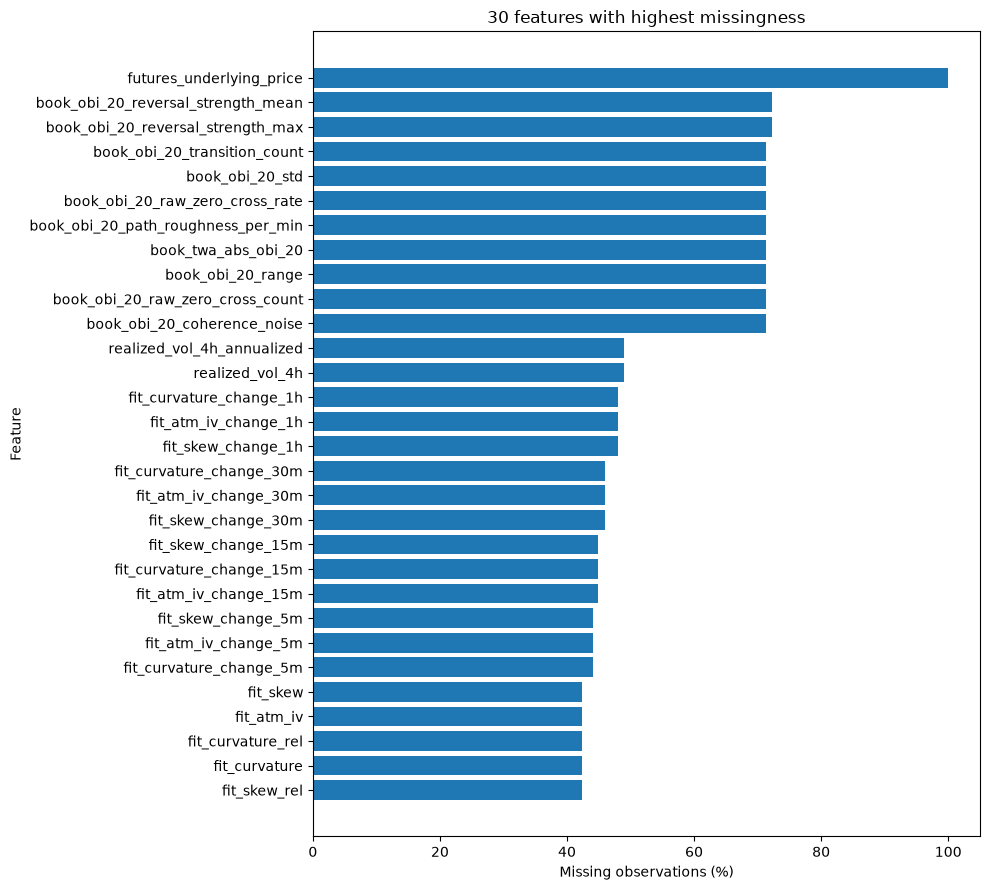

In [85]:
top_missing = missingness.head(30).sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_missing["column"], top_missing["missing_pct"])
ax.set_xlabel("Missing observations (%)")
ax.set_ylabel("Feature")
ax.set_title("30 features with highest missingness")
plt.tight_layout()
plt.show()

## 8. Readiness coverage

In [86]:
readiness_columns = [c for c in [
    "collection_complete",
    "price_features_ready",
    "state_research_ready",
    "l2_boundary_ready",
    "l2_intrawindow_ready",
    "realized_vol_30m_ready",
    "realized_vol_1h_ready",
    "realized_vol_4h_ready",
    "core_smile_usable",
    "core_surface_change_5m_ready",
    "delta_25d_smile_available",
    "delta_25d_change_5m_ready",
    "structural_level_features_ready",
    "structural_dynamic_features_ready",
    "microstructure_features_ready",
    "instability_features_ready",
] if c in features.columns]

readiness_summary = []
for col in readiness_columns:
    true_count = int(features[col].fillna(False).sum())
    readiness_summary.append({
        "flag": col,
        "true": true_count,
        "false_or_null": len(features) - true_count,
        "coverage_pct": 100.0 * true_count / len(features),
    })

readiness_summary = pd.DataFrame(readiness_summary).sort_values("coverage_pct", ascending=False).reset_index(drop=True)
display(readiness_summary)

,flag,true,false_or_null,coverage_pct
0,core_smile_usable,31556,2716,92.075163
1,collection_complete,30002,4270,87.540850
2,price_features_ready,29554,4718,86.233660
3,state_research_ready,29477,4795,86.008987
4,structural_level_features_ready,28950,5322,84.471289
5,l2_boundary_ready,28105,6167,82.005719
6,l2_intrawindow_ready,27685,6587,80.780229
7,microstructure_features_ready,27563,6709,80.424253
8,realized_vol_30m_ready,27286,6986,79.616013
9,core_surface_change_5m_ready,26927,7345,78.568511


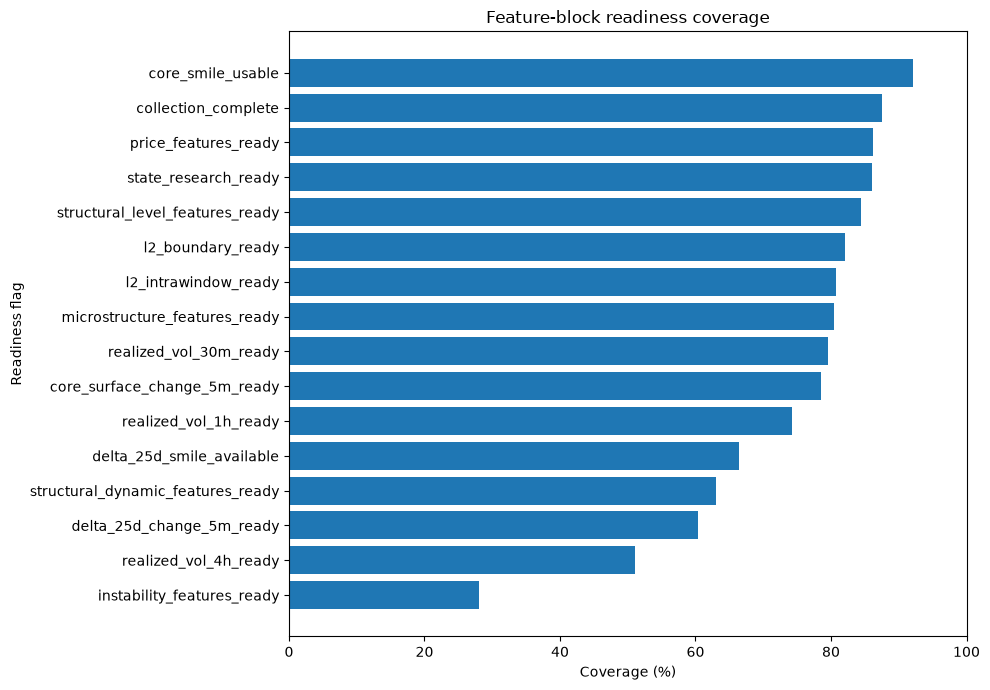

In [87]:
fig, ax = plt.subplots(figsize=(10, 7))
ordered_flags = readiness_summary.sort_values("coverage_pct")
ax.barh(ordered_flags["flag"], ordered_flags["coverage_pct"])
ax.set_xlim(0, 100)
ax.set_xlabel("Coverage (%)")
ax.set_ylabel("Readiness flag")
ax.set_title("Feature-block readiness coverage")
plt.tight_layout()
plt.show()

## 9. Numeric features, infinities, and quantiles

In [88]:
numeric_columns = features.select_dtypes(include=[np.number]).columns.tolist()
boolean_columns = [c for c in features.columns if str(features[c].dtype) in {"bool", "boolean"}]
numeric_feature_columns = [c for c in numeric_columns if c not in boolean_columns]

print(f"Numeric columns:         {len(numeric_columns)}")
print(f"Numeric feature columns: {len(numeric_feature_columns)}")
print(f"Boolean columns:         {len(boolean_columns)}")

Numeric columns:         148
Numeric feature columns: 148
Boolean columns:         49


In [89]:
infinity_rows = []
for col in numeric_feature_columns:
    arr = pd.to_numeric(features[col], errors="coerce").to_numpy(dtype=float, na_value=np.nan)
    pos_inf = int(np.isposinf(arr).sum())
    neg_inf = int(np.isneginf(arr).sum())
    if pos_inf or neg_inf:
        infinity_rows.append({"column": col, "positive_inf": pos_inf, "negative_inf": neg_inf})

infinity_summary = pd.DataFrame(infinity_rows, columns=["column", "positive_inf", "negative_inf"])
print(f"Columns containing ±inf: {len(infinity_summary)}")
display(infinity_summary)

Columns containing ±inf: 0


,column,positive_inf,negative_inf


In [90]:
quantiles = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
summary_rows = []

for col in numeric_feature_columns:
    s = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    row = {
        "column": col,
        "n": len(s),
        "missing_pct": 100.0 * (len(features) - len(s)) / len(features),
    }
    if len(s):
        row.update({"mean": s.mean(), "std": s.std(), "min": s.min(), "max": s.max()})
        for q, value in s.quantile(quantiles).items():
            row[f"q_{q:g}"] = value
    summary_rows.append(row)

numeric_summary = pd.DataFrame(summary_rows)
display(numeric_summary)

,column,n,missing_pct,mean,std,min,max,q_0.001,q_0.01,q_0.05,q_0.25,q_0.5,q_0.75,q_0.95,q_0.99,q_0.999
0,minutes_to_expiry,34272,0.000000,7.225000e+02,4.156958e+02,5.000000e+00,1.440000e+03,5.000000e+00,15.000000,75.000000,363.750000,722.500000,1.081250e+03,1.370000e+03,1.430000e+03,1.440000e+03
1,utc_hour,34272,0.000000,1.150000e+01,6.922288e+00,0.000000e+00,2.300000e+01,0.000000e+00,0.000000,1.000000,5.750000,11.500000,1.725000e+01,2.200000e+01,2.300000e+01,2.300000e+01
2,utc_minute_of_day,34272,0.000000,7.175000e+02,4.156958e+02,0.000000e+00,1.435000e+03,0.000000e+00,10.000000,70.000000,358.750000,717.500000,1.076250e+03,1.365000e+03,1.425000e+03,1.435000e+03
3,utc_day_of_week,34272,0.000000,4.039216e+00,2.141689e+00,1.000000e+00,7.000000e+00,1.000000e+00,1.000000,1.000000,2.000000,4.000000,6.000000e+00,7.000000e+00,7.000000e+00,7.000000e+00
4,integrity_flag_count,34272,0.000000,1.361753e-01,3.800283e-01,0.000000e+00,5.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00,1.000000e+00,4.000000e+00
5,settlement_locked_fraction,34272,0.000000,8.680556e-03,7.231587e-02,0.000000e+00,8.333333e-01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,5.000000e-01,8.333333e-01
6,minutes_since_session_start,34272,0.000000,7.175000e+02,4.156958e+02,0.000000e+00,1.435000e+03,0.000000e+00,10.000000,70.000000,358.750000,717.500000,1.076250e+03,1.365000e+03,1.425000e+03,1.435000e+03
7,session_progress_fraction,34272,0.000000,4.982639e-01,2.886776e-01,0.000000e+00,9.965278e-01,0.000000e+00,0.006944,0.048611,0.249132,0.498264,7.473958e-01,9.479167e-01,9.895833e-01,9.965278e-01
8,futures_tradable_mid_price,29981,12.520425,1.251610e+04,2.948205e+04,3.317900e-01,8.729200e+04,3.325699e-01,0.333770,0.335390,1.533050,91.349500,2.681855e+03,8.487105e+04,8.639563e+04,8.685610e+04
9,futures_mark_price,29981,12.520425,1.251619e+04,2.948227e+04,3.317270e-01,8.730491e+04,3.325766e-01,0.333784,0.335406,1.533000,91.340000,2.681900e+03,8.487123e+04,8.639493e+04,8.685620e+04


## 10. Constant and near-constant features

`dominant_share` is the fraction of non-null observations occupied by the most frequent value.

In [91]:
constant_rows = []
for col in features.columns:
    s = features[col].dropna()
    if len(s) == 0:
        constant_rows.append({"column": col, "non_null": 0, "unique": 0, "dominant_share": np.nan, "status": "all_missing"})
        continue
    counts = s.value_counts(dropna=True)
    unique = int(len(counts))
    dominant_share = float(counts.iloc[0] / len(s))
    status = None
    if unique == 1:
        status = "constant"
    elif dominant_share >= 0.995:
        status = "near_constant"
    if status:
        constant_rows.append({"column": col, "non_null": len(s), "unique": unique, "dominant_share": dominant_share, "status": status})

constant_summary = pd.DataFrame(constant_rows)
if not constant_summary.empty:
    constant_summary = constant_summary.sort_values(["status", "dominant_share"], ascending=[True, False], na_position="last").reset_index(drop=True)
display(constant_summary)

,column,non_null,unique,dominant_share,status
0,futures_underlying_price,0,0,NaN,all_missing
1,us_dst,34272,1,1.000000,constant
2,eu_dst,34272,1,1.000000,constant
3,market_reference_source,29981,1,1.000000,constant
4,market_reference_is_tradable,29981,1,1.000000,constant
5,return_source,34272,1,1.000000,constant
6,primary_option_instrument_type,31766,1,1.000000,constant
7,primary_option_settlement_currency,31766,1,1.000000,constant
8,primary_option_api_currency,31766,1,1.000000,constant
9,option_family_selection_reason,31766,1,1.000000,constant


## 11. Temporal continuity

The canonical grid should preserve expected 5-minute timestamps. This verifies that the time index itself has not developed irregular gaps.

In [92]:
ordered = features[["underlying", "state_time", "state_id"]].sort_values(["underlying", "state_time"]).copy()
ordered["delta_minutes"] = ordered.groupby("underlying")["state_time"].diff().dt.total_seconds().div(60.0)
irregular = ordered[ordered["delta_minutes"].notna() & (ordered["delta_minutes"] != 5.0)]

gap_summary = (
    irregular.groupby("underlying")
    .agg(
        irregular_intervals=("delta_minutes", "size"),
        min_gap_minutes=("delta_minutes", "min"),
        max_gap_minutes=("delta_minutes", "max"),
    )
    .reset_index()
)

print(f"Irregular asset-level timestamp intervals: {len(irregular):,}")
display(gap_summary)

Irregular asset-level timestamp intervals: 0


,underlying,irregular_intervals,min_gap_minutes,max_gap_minutes


## 12. Feature availability by asset

In [93]:
candidate_features = [c for c in [
    "return_5m",
    "realized_vol_1h",
    "option_iv_atm_forward",
    "option_skew_025",
    "option_curvature_025",
    "atm_iv_change_5m",
    "skew_025_change_5m",
    "curvature_025_change_5m",
    "rr_25d",
    "bf_25d",
    "book_twa_obi_20",
    "book_obi_20_std",
    "book_obi_20_path_roughness_per_min",
    "book_obi_20_coherence_noise",
] if c in features.columns]

availability_by_asset = []
for asset, group in features.groupby("underlying"):
    row = {"underlying": asset, "rows": len(group)}
    for col in candidate_features:
        row[f"{col}_pct"] = 100.0 * group[col].notna().mean()
    availability_by_asset.append(row)

availability_by_asset = pd.DataFrame(availability_by_asset).sort_values("underlying")
display(availability_by_asset)

,underlying,rows,return_5m_pct,realized_vol_1h_pct,option_iv_atm_forward_pct,option_skew_025_pct,option_curvature_025_pct,atm_iv_change_5m_pct,skew_025_change_5m_pct,curvature_025_change_5m_pct,rr_25d_pct,bf_25d_pct,book_twa_obi_20_pct,book_obi_20_std_pct,book_obi_20_path_roughness_per_min_pct,book_obi_20_coherence_noise_pct
0,AVAX,4896,85.028595,74.325980,92.422386,92.422386,92.422386,88.031046,82.209967,82.209967,83.353758,83.353758,82.046569,28.71732,28.71732,28.71732
1,BTC,4896,85.028595,74.325980,92.422386,92.422386,92.422386,89.379085,79.922386,79.922386,58.333333,58.333333,82.046569,28.71732,28.71732,28.71732
2,ETH,4896,85.028595,74.325980,92.422386,92.422386,92.422386,89.338235,79.411765,79.411765,62.745098,62.745098,82.046569,28.71732,28.71732,28.71732
3,HYPE,4896,85.028595,74.325980,92.422386,92.422386,92.422386,88.255719,76.307190,76.307190,72.998366,72.998366,82.046569,28.71732,28.71732,28.71732
4,SOL,4896,85.028595,74.325980,92.422386,92.422386,92.422386,87.173203,72.773693,72.773693,79.248366,79.248366,82.046569,28.71732,28.71732,28.71732
5,TRX,4896,84.987745,74.060458,92.422386,92.422386,92.422386,89.133987,83.884804,83.884804,36.397059,36.397059,82.046569,28.71732,28.71732,28.71732
6,XRP,4896,85.028595,74.325980,92.116013,89.991830,89.991830,85.008170,75.469771,75.469771,71.405229,71.405229,82.046569,28.71732,28.71732,28.71732


## 13. Core distribution snapshot

This is only a first look. Dedicated notebooks will examine transformations, ECDFs, tails, autocorrelation, conditioning, and cross-feature relationships.

In [94]:
distribution_features = [c for c in [
    "return_5m",
    "realized_vol_1h_annualized",
    "log1p_volume_usd",
    "trade_flow_imbalance",
    "futures_spread_bps",
    "perpetual_mid_vs_index_bps",
    "book_twa_obi_20",
    "option_iv_atm_forward",
    "option_skew_025",
    "option_curvature_025",
    "atm_iv_change_5m",
] if c in features.columns]

distribution_snapshot = numeric_summary[numeric_summary["column"].isin(distribution_features)].set_index("column").reindex(distribution_features).reset_index()
display(distribution_snapshot)

,column,n,missing_pct,mean,std,min,max,q_0.001,q_0.01,q_0.05,q_0.25,q_0.5,q_0.75,q_0.95,q_0.99,q_0.999
0,return_5m,29139,14.977241,0.000002,0.001841,-0.023029,0.021486,-0.011024,-0.005399,-0.002727,-0.000692,0.000000,0.000694,0.002785,0.005355,0.010526
1,realized_vol_1h_annualized,25460,25.711951,0.473125,0.350401,0.015175,2.669111,0.030445,0.054776,0.089718,0.213486,0.382632,0.644482,1.115850,1.685026,2.519842
2,log1p_volume_usd,30009,12.438725,8.539612,4.285897,0.000000,18.381071,0.000000,0.000000,0.000000,6.886390,9.584349,11.426862,13.958590,15.403483,16.427559
3,trade_flow_imbalance,25682,25.064192,-0.022525,0.654080,-1.000000,1.000000,-1.000000,-1.000000,-1.000000,-0.566088,-0.006061,0.470183,1.000000,1.000000,1.000000
4,futures_spread_bps,29981,12.520425,2.471917,18.993398,0.011464,2139.637859,0.011521,0.011580,0.011791,0.037363,0.926023,3.121225,5.852714,7.772381,328.927522
5,perpetual_mid_vs_index_bps,29981,12.520425,2.624136,8.367753,-87.965324,1012.713340,-23.788700,-5.858160,-2.445921,1.151595,2.581755,3.884818,7.226396,10.253291,40.695096
6,book_twa_obi_20,28119,17.953431,-0.008504,0.155051,-0.807421,0.714406,-0.611076,-0.466017,-0.296945,-0.074565,0.002572,0.069907,0.216655,0.423536,0.632578
7,option_iv_atm_forward,31660,7.621382,47.924916,23.559319,8.654510,457.556512,10.882055,13.349824,18.253836,26.330525,44.588690,64.787464,89.226408,109.259205,128.574730
8,option_skew_025,31556,7.924837,3.217686,9.183137,-56.083210,379.486618,-47.425761,-16.868270,-8.526105,-0.691955,2.972683,6.921875,15.412164,24.652415,64.280729
9,option_curvature_025,31556,7.924837,9.066853,8.103467,-416.786227,198.451851,-13.974938,-1.487461,0.816034,3.720365,7.773807,12.959176,21.857407,33.515847,50.789051


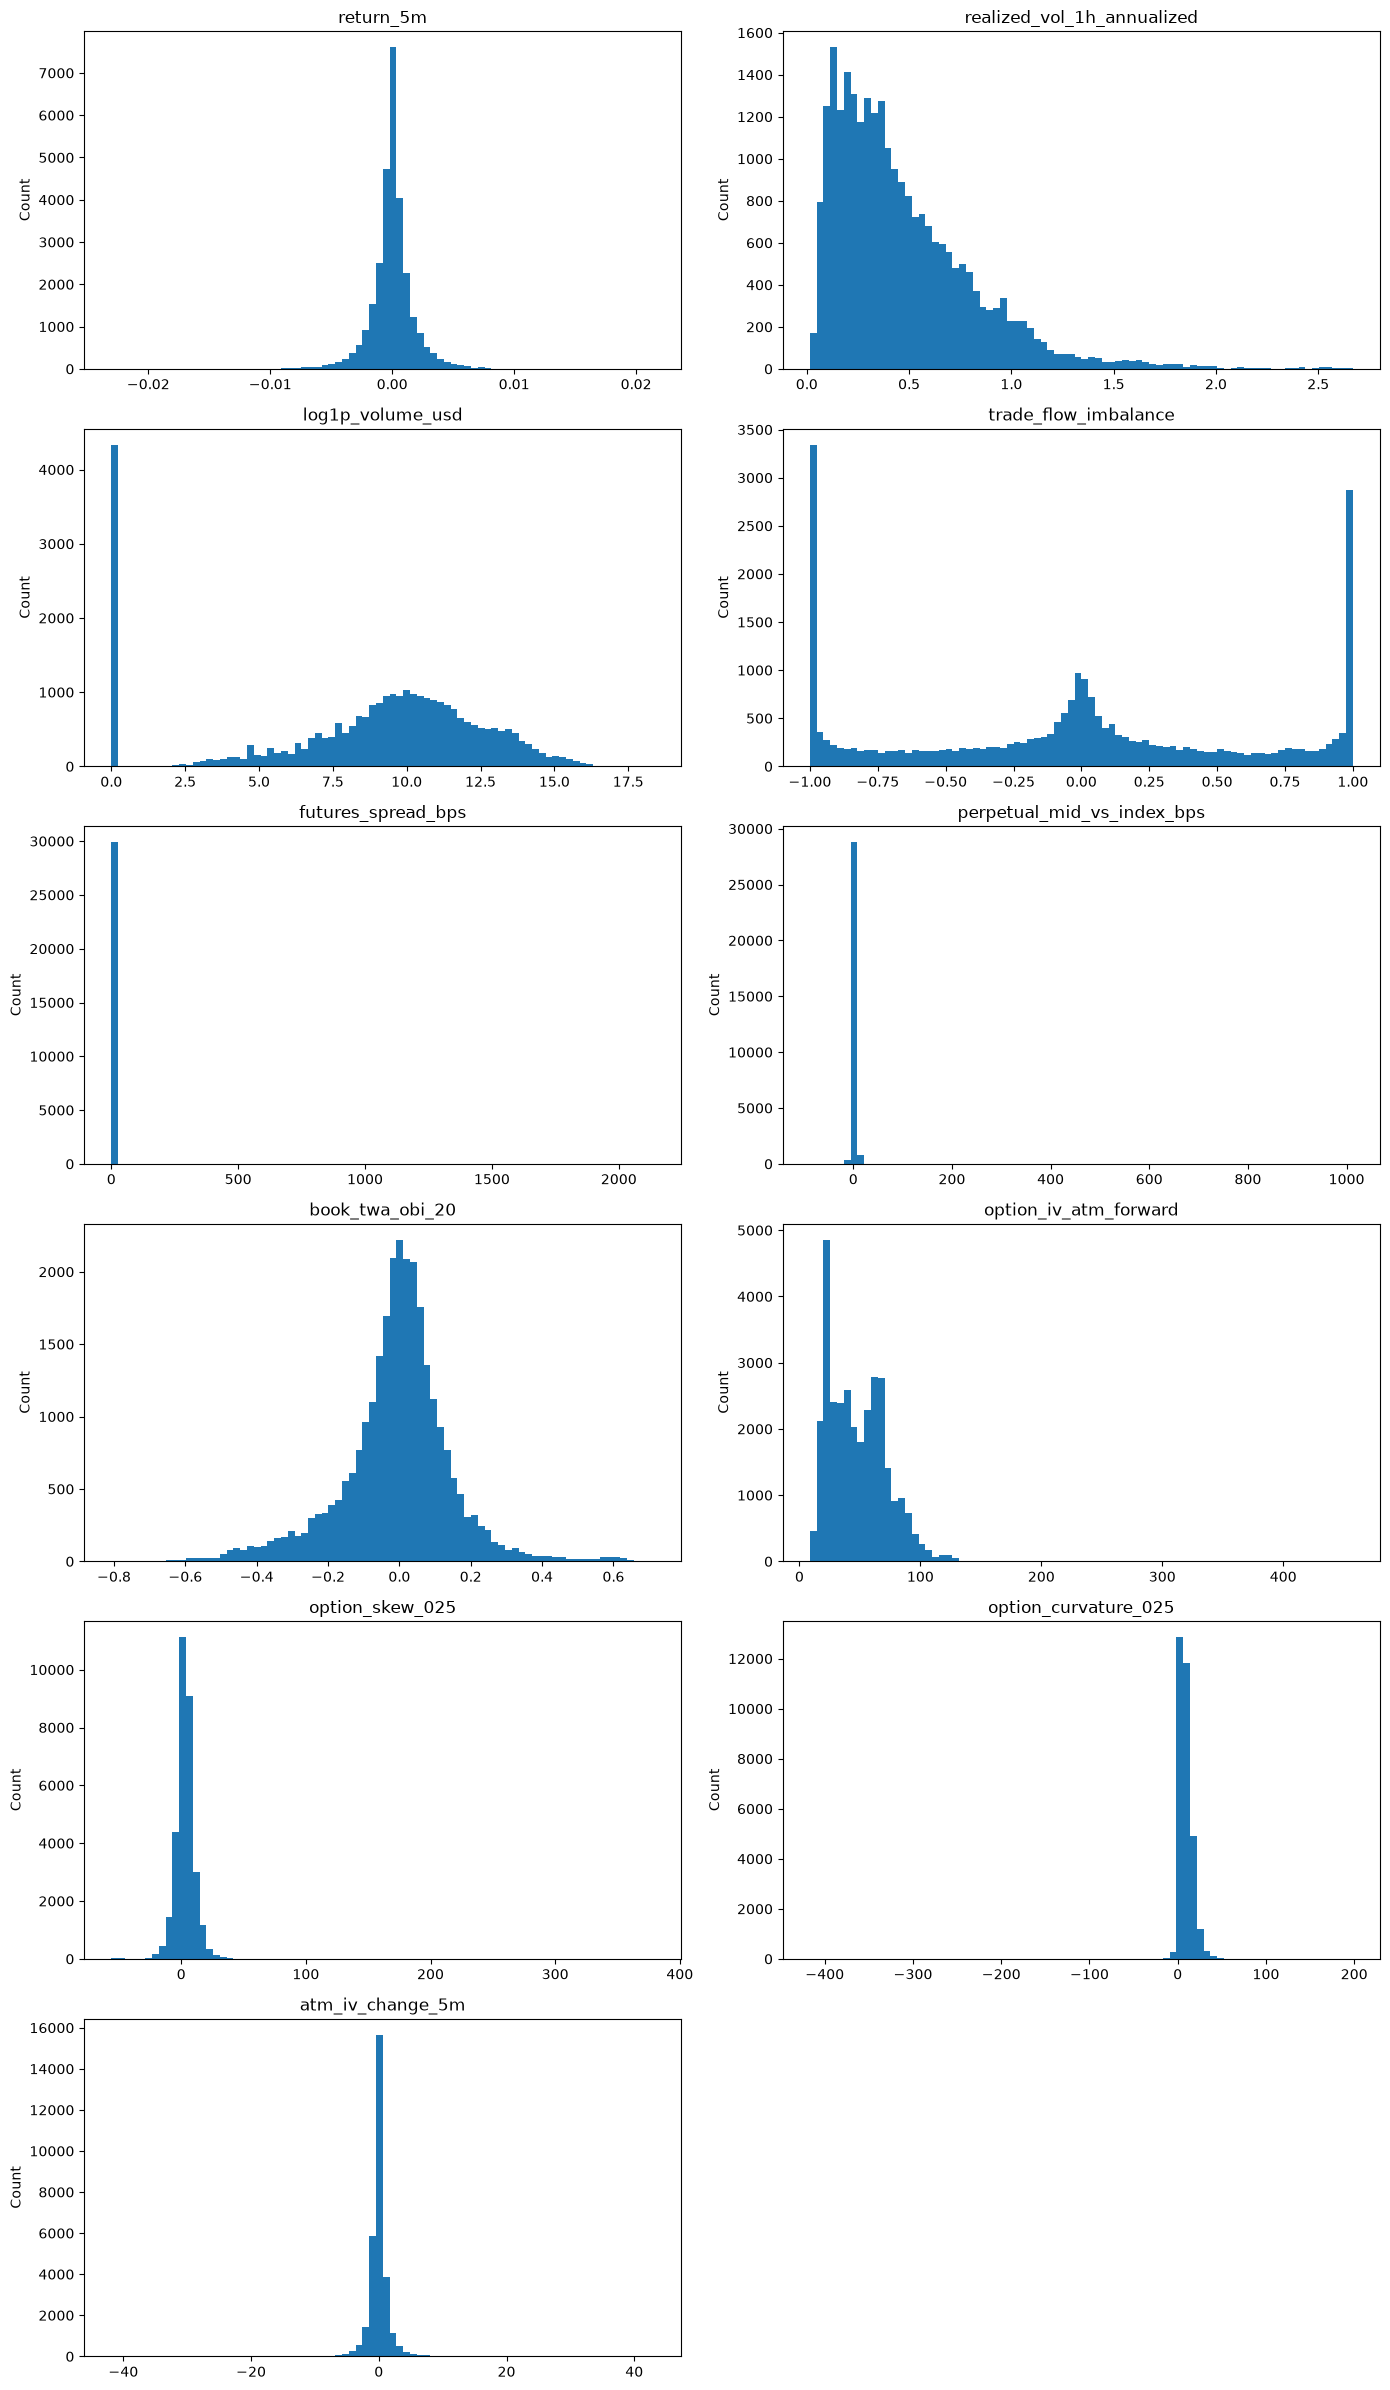

In [95]:
if distribution_features:
    ncols = 2
    nrows = math.ceil(len(distribution_features) / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, distribution_features):
        s = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if len(s):
            ax.hist(s, bins=80)
            ax.set_title(col)
            ax.set_ylabel("Count")
        else:
            ax.text(0.5, 0.5, "No available observations", ha="center", va="center")
            ax.set_title(col)

    for ax in axes[len(distribution_features):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## 14. Option-family inventory

The final matrix uses one stable primary family, but the long-form table retains all families for robustness research.

In [96]:
if "option_surface_feature_state" in set(relations["table_name"]):
    option_family_inventory = con.execute(
        """
        SELECT
            underlying,
            option_family_id,
            COUNT(*) AS states,
            SUM(CASE WHEN core_smile_usable THEN 1 ELSE 0 END) AS core_usable,
            SUM(CASE WHEN core_surface_change_5m_ready THEN 1 ELSE 0 END) AS dynamic_5m,
            SUM(CASE WHEN delta_25d_smile_available THEN 1 ELSE 0 END) AS delta_25d
        FROM option_surface_feature_state
        GROUP BY underlying, option_family_id
        ORDER BY underlying, option_family_id
        """
    ).df()
    display(option_family_inventory)
else:
    print("option_surface_feature_state is not available.")

,underlying,option_family_id,states,core_usable,dynamic_5m,delta_25d
0,AVAX,AVAX|linear|USDC|USDC,4538,4525.0,4025.0,4081.0
1,BTC,BTC|linear|USDC|USDC,4538,4525.0,3913.0,2856.0
2,BTC,BTC|reversed|BTC|BTC,4538,4525.0,3962.0,2857.0
3,ETH,ETH|linear|USDC|USDC,4538,4525.0,3888.0,3072.0
4,ETH,ETH|reversed|ETH|ETH,4538,4525.0,3943.0,3077.0
5,HYPE,HYPE|linear|USDC|USDC,4538,4525.0,3736.0,3574.0
6,SOL,SOL|linear|USDC|USDC,4538,4525.0,3563.0,3880.0
7,TRX,TRX|linear|USDC|USDC,4538,4525.0,4107.0,1782.0
8,XRP,XRP|linear|USDC|USDC,4538,4406.0,3695.0,3496.0


## 15. L2-instability availability

Historical rows must stay unavailable before the collector upgrade. This verifies first availability by asset without fabricating history.

In [97]:
l2_columns = [c for c in [
    "book_twa_abs_obi_20",
    "book_obi_20_std",
    "book_obi_20_path_roughness_per_min",
    "book_obi_20_range",
    "book_obi_20_coherence_noise",
    "book_obi_20_raw_zero_cross_rate",
    "book_obi_20_reversal_strength_mean",
    "book_obi_20_reversal_strength_max",
] if c in features.columns]

l2_availability = []
for asset, group in features.groupby("underlying"):
    row = {"underlying": asset}
    for col in l2_columns:
        available = group[col].notna()
        row[f"{col}_n"] = int(available.sum())
        row[f"{col}_first"] = group.loc[available, "state_time"].min() if available.any() else pd.NaT
    l2_availability.append(row)

display(pd.DataFrame(l2_availability))

,underlying,book_twa_abs_obi_20_n,book_twa_abs_obi_20_first,book_obi_20_std_n,book_obi_20_std_first,book_obi_20_path_roughness_per_min_n,book_obi_20_path_roughness_per_min_first,book_obi_20_range_n,book_obi_20_range_first,book_obi_20_coherence_noise_n,book_obi_20_coherence_noise_first,book_obi_20_raw_zero_cross_rate_n,book_obi_20_raw_zero_cross_rate_first,book_obi_20_reversal_strength_mean_n,book_obi_20_reversal_strength_mean_first,book_obi_20_reversal_strength_max_n,book_obi_20_reversal_strength_max_first
0,AVAX,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1382,2026-10-01 10:50:00+00:00,1382,2026-10-01 10:50:00+00:00
1,BTC,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1398,2026-10-01 10:50:00+00:00,1398,2026-10-01 10:50:00+00:00
2,ETH,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1395,2026-10-01 10:50:00+00:00,1395,2026-10-01 10:50:00+00:00
3,HYPE,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1404,2026-10-01 10:50:00+00:00,1404,2026-10-01 10:50:00+00:00
4,SOL,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1405,2026-10-01 10:50:00+00:00,1405,2026-10-01 10:50:00+00:00
5,TRX,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1135,2026-10-01 10:55:00+00:00,1135,2026-10-01 10:55:00+00:00
6,XRP,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1406,2026-10-01 10:50:00+00:00,1376,2026-10-01 10:50:00+00:00,1376,2026-10-01 10:50:00+00:00


## 16. Coverage through the 0DTE session

We do not impose arbitrary time-to-expiry bins here. This simply shows raw coverage as a function of minutes to expiry.

,minutes_to_expiry,states,research_ready,structural_dynamic
287,1440,119,42,0
286,1435,119,98,15
285,1430,119,98,73
284,1425,119,98,84
283,1420,119,98,86
282,1415,119,98,91
281,1410,119,91,87
280,1405,119,98,87
279,1400,119,91,76
278,1395,119,91,77


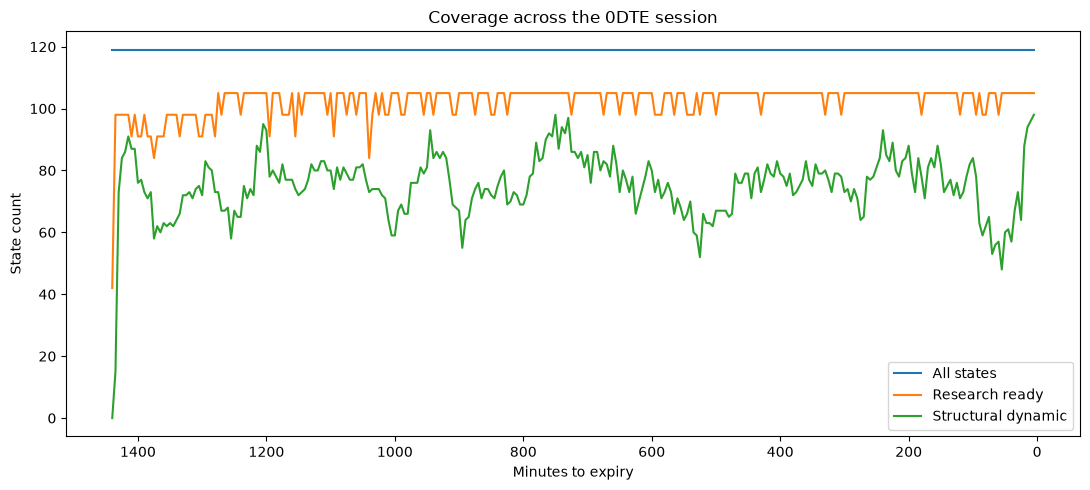

In [98]:
if "minutes_to_expiry" in features.columns:
    session_progress = (
        features.groupby("minutes_to_expiry")
        .agg(
            states=("state_id", "size"),
            research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
            structural_dynamic=("structural_dynamic_features_ready", lambda s: int(s.fillna(False).sum())),
        )
        .reset_index()
        .sort_values("minutes_to_expiry", ascending=False)
    )

    display(session_progress.head(20))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(session_progress["minutes_to_expiry"], session_progress["states"], label="All states")
    ax.plot(session_progress["minutes_to_expiry"], session_progress["research_ready"], label="Research ready")
    ax.plot(session_progress["minutes_to_expiry"], session_progress["structural_dynamic"], label="Structural dynamic")
    ax.invert_xaxis()
    ax.set_xlabel("Minutes to expiry")
    ax.set_ylabel("State count")
    ax.set_title("Coverage across the 0DTE session")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 17. Inventory report objects

In [99]:
inventory_report = {
    "overview": overview,
    "asset_counts": asset_counts,
    "expiry_counts": expiry_counts,
    "dtypes": dtype_inventory,
    "missingness": missingness,
    "readiness": readiness_summary,
    "numeric_summary": numeric_summary,
    "constant_features": constant_summary,
    "irregular_gaps": gap_summary,
    "availability_by_asset": availability_by_asset,
}

print("Inventory report sections:")
for name, frame in inventory_report.items():
    print(f"  {name:<24} {len(frame):>6,} rows")

Inventory report sections:
  overview                      8 rows
  asset_counts                  7 rows
  expiry_counts                17 rows
  dtypes                      223 rows
  missingness                 223 rows
  readiness                    16 rows
  numeric_summary             148 rows
  constant_features            19 rows
  irregular_gaps                0 rows
  availability_by_asset         7 rows


## 18. Interpretation checklist

Before moving to `02_market_distributions.ipynb`, verify:

1. uniqueness checks are zero;
2. expected assets have expected state counts;
3. missingness is explainable by readiness/history rather than unexplained corruption;
4. no candidate numeric features contain infinities;
5. no important features are constant or nearly constant;
6. timestamp gaps are understood;
7. readiness degradation clusters are understood;
8. delta-smile sparsity is materially higher than fixed-moneyness sparsity where expected;
9. L2-instability features begin only after real collection starts;
10. features with unusual tails/scales are identified for dedicated analysis.

No transformation should be promoted into production solely from this notebook.

In [100]:
# Close the read-only connection when finished.
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
